# TP 4 : Le modèle complet

On rassemble les TP 1 à 3 et on entraîne. Le vecteur d'un caractère est réécrit par son passé avant de devenir des scores.


In [1]:
import os
from urllib.request import urlretrieve

import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

torch.manual_seed(1337)

batch_size = 16       # B, nombre de fenêtres par pas
block_size = 32       # T, longueur max du contexte
max_iters = 5000      # nombre de pas ; c'est ça qu'on baisse d'abord sur CPU
eval_interval = 500   # tous les combien de pas on mesure train et val
learning_rate = 1e-3  # taux d'Adam, plus petit que pour la table du TP 1
eval_iters = 50       # nombre de batchs moyennés pour une loss stable
n_embd = 64           # taille du vecteur de chaque token
n_head = 4            # nombre de têtes ; dh = n_embd / n_head
n_layer = 4           # nombre de blocs attention + MLP
dropout = 0.0         # 0 au début ; on l'augmente si la val remonte

device = "cuda" if torch.cuda.is_available() else "cpu"
assert n_embd % n_head == 0
print("device", device, "| dh", n_embd // n_head, "| tokens / batch", batch_size * block_size)

url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
if not os.path.exists("input.txt"):
    urlretrieve(url, "input.txt")
with open("input.txt", encoding="utf-8") as f:
    text = f.read()

chars = sorted(set(text))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join(itos[i] for i in ids)

data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]

def get_batch(split):
    source = train_data if split == "train" else val_data
    # on retire block_size pour que la cible tienne encore dans le tableau
    starts = torch.randint(len(source) - block_size, (batch_size,))
    x = torch.stack([source[i : i + block_size] for i in starts])
    y = torch.stack([source[i + 1 : i + block_size + 1] for i in starts])
    return x.to(device), y.to(device)


device cpu | dh 16 | tokens / batch 512


## Étape 0 : Les constantes

dh = n_embd / n_head = 64 / 4 = 16. Un batch contient batch_size × block_size = 16 × 32 = 512 tokens, donc 512 prédictions par pas. Sur CPU, la variable à baisser en premier pour tester est max_iters : le modèle reste le même, seul le nombre de pas change. Si la mémoire manque, on baisse ensuite batch_size.


In [2]:
class Head(nn.Module):
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        # masque causal, pas un poids : il suit le modèle sur le GPU sans être appris
        self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)  # éteint des liens d'attention pendant l'entraînement

    def forward(self, x):
        B, T, C = x.shape
        k, q = self.key(x), self.query(x)
        # on divise par sqrt(dh), pas par sqrt(C) : le produit scalaire est en dimension dh
        wei = q @ k.transpose(-2, -1) * k.size(-1) ** -0.5
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float("-inf"))
        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)
        return wei @ self.value(x)

class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # dernière dimension : 4 têtes de dh recoivent n_embd
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        return self.dropout(self.proj(out))

class FeedForward(nn.Module):
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    def __init__(self, n_embd, n_head):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        # pré-norm : on normalise, on calcule un déplacement, on l'ajoute
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x


## Étapes 1 à 3 : Tête, plusieurs têtes, bloc

On divise par k.size(-1), donc par √dh, et pas par √C. C ici vaut n_embd, la taille du vecteur complet. Le produit scalaire, lui, est fait dans la tête, en dimension dh. On tronque tril avec [:T, :T] parce qu'au début de la génération T vaut 1, pas block_size. Le masque est un buffer : il n'est pas appris, il suit juste le modèle sur le GPU.

On concatène les têtes sur la dernière dimension, celle des features. 4 × 16 redonne n_embd. Si n_embd n'était pas divisible par n_head, dh ne serait pas entier et la concaténation ne retomberait pas sur la bonne largeur : le résidu x + attention(x) casserait. La projection proj mélange ensuite les têtes. Sans elle, elles resteraient juste côte à côte.

Dans le bloc, l'ordre est LayerNorm, puis attention ou MLP, puis l'addition. L'attention est la communication : la position t dépend des positions ≤ t. Le MLP est le calcul : la même transformation partout, sans regarder les voisins.


In [3]:
class BigramLanguageModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)      # qui est ce caractère
        self.position_embedding_table = nn.Embedding(block_size, n_embd)  # où il est dans la fenêtre
        self.blocks = nn.Sequential(*[Block(n_embd, n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)  # état -> scores sur le vocabulaire

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok = self.token_embedding_table(idx)                         # (B, T, n_embd)
        pos = self.position_embedding_table(torch.arange(T, device=idx.device))  # (T, n_embd)
        x = tok + pos                                                 # le T se diffuse sur B
        x = self.ln_f(self.blocks(x))
        logits = self.lm_head(x)                                      # (B, T, vocab)
        if targets is None:
            return logits, None
        loss = F.cross_entropy(logits.reshape(B * T, -1), targets.reshape(B * T))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -block_size:]  # la table de positions ne va pas plus loin que T
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :]
            probs = F.softmax(logits, dim=-1)
            idx = torch.cat((idx, torch.multinomial(probs, 1)), dim=1)
        return idx

model = BigramLanguageModel().to(device)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.3f} M paramètres")
xb, yb = get_batch("train")
logits, loss = model(xb, yb)
print("logits", tuple(logits.shape), "loss", round(loss.item(), 3))


0.210 M paramètres
logits (16, 32, 65) loss 4.382


## Étapes 4 à 6 : Embeddings, loss, génération

Trois matrices. L'embedding de token fait (vocab, n_embd) : quel caractère c'est. L'embedding de position fait (block_size, n_embd) : où il est dans la fenêtre. lm_head est un Linear(n_embd, vocab) : il lit un état et sort un score par caractère. Au TP 1 c'était la même table, parce que l'état était déjà les logits. Ici les deux tailles sont différentes, et un vecteur utile pour l'attention n'est pas forcément une bonne lecture vers les caractères.

tok + pos passe par broadcasting : (B, T, C) + (T, C) s'aligne par la droite, le B est recopié. On n'aplatit les logits que quand il y a des cibles. À la génération il faut garder l'axe du temps pour lire le dernier pas.

@torch.no_grad() coupe le graphe : on ne met aucun poids à jour, le stocker ne sert à rien. On recoupe le contexte à block_size parce que la table de positions n'a pas de ligne au-delà. On tire avec multinomial plutôt que argmax, sinon le texte boucle sur le caractère le plus fréquent.


In [4]:
def ecrire(modele, n):
    modele.eval()
    idx = torch.zeros((1, 1), dtype=torch.long, device=device)
    texte = decode(modele.generate(idx, n)[0].tolist())
    modele.train()
    return texte

print("--- avant ---")
print(ecrire(model, 250))


--- avant ---



.mBP.A XPjQOl;-QfYbxwgHgyvp'VE,nqfoaUorzzcCTfJAqzXFyp?lgsuNs:GriKfXJsFN'r!QrbFcUWWQ
:KXN.;PreFoeIWszlJXFLKYdMcUNUNYRK,
RysopWvfmYxcjeRJJcuAfJDRew
LOvzFV;3XNnokWoo?derEahBRoHQWgoKkfoJAdVkK-TEUKOJOeLfVvodJLR;eXbcXJJAJpciiFOzzpbsDjcWwTEV&,ppJE,$&reszTd?


In [5]:
@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()  # dropout coupé le temps de mesurer
    for split in ("train", "val"):
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            _, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out

opt = torch.optim.AdamW(model.parameters(), lr=learning_rate)
historique = []

for iteration in range(max_iters):
    if iteration % eval_interval == 0 or iteration == max_iters - 1:
        mesures = estimate_loss()
        historique.append((iteration, mesures["train"], mesures["val"]))
        print(f"pas {iteration:4d}  train {mesures['train']:.3f}  val {mesures['val']:.3f}")

    xb, yb = get_batch("train")
    _, loss = model(xb, yb)
    opt.zero_grad(set_to_none=True)
    loss.backward()
    opt.step()


pas    0  train 4.415  val 4.401


pas  500  train 2.250  val 2.250


pas 1000  train 2.052  val 2.073


pas 1500  train 1.935  val 1.970


pas 2000  train 1.846  val 1.953


pas 2500  train 1.808  val 1.927


pas 3000  train 1.770  val 1.921


pas 3500  train 1.732  val 1.870


pas 4000  train 1.691  val 1.838


pas 4500  train 1.687  val 1.839


pas 4999  train 1.668  val 1.806


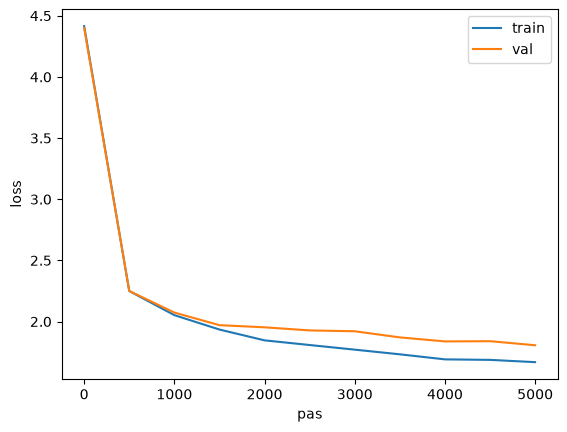

--- après ---



To he pleadys wife will the pagres
Weo his nother But, women fortune the resecused folm,
And love this for of name'd a coll and rathen;
I washer kee thee is my fach merine?

MENENENIUS:
O, suparl'd is--

PAULIUS:
The speak woes you couty; deathrounce!

QUEEN BOLINGBROKE:
Cearen, she requisanate torthe hourty, or a fultis were!
Where princess: they hads this ressime,
Sirs my scoundry puch timsterable
Struty to dides dior canded to sight, my
As shall death,
Alard, it
The to proad'd himself have keedny?

PRIARSAMEY:
Rend they like first he were your theirs:
What I haved I can my moe carriqued;
The such prase sir, sir; we s-love in in them.
Whe'll father for then by say your just,
The deeps of theirs with of thy to
you of the fault is worther
And Morter her crease thy bery your father stall'd



In [6]:
pas = [h[0] for h in historique]
plt.plot(pas, [h[1] for h in historique], label="train")
plt.plot(pas, [h[2] for h in historique], label="val")
plt.xlabel("pas")
plt.ylabel("loss")
plt.legend()
plt.show()

print("--- après ---")
print(ecrire(model, 800))


## Étapes 7 et 8 : Évaluer et entraîner

model.eval() puis model.train() change le dropout. En évaluation on veut la prédiction complète, pas un sous-réseau tiré au hasard. Avec dropout = 0 ça ne change rien, mais il faut le faire dès qu'on met du dropout.

La loss part de ln(65) ≈ 4,2. Le bigramme du TP 1 plafonnait vers 2,5. Si on passe en dessous, le gain vient du contexte : l'attention a lu autre chose que le dernier caractère. Le texte n'est pas de l'anglais correct. On y cherche des sauts de ligne, des mots, parfois un nom en capitales.

Si la loss d'entraînement baisse et que la validation remonte, le modèle mémorise les fenêtres du train au lieu de généraliser. On s'arrête plus tôt, on augmente le dropout, ou on réduit le modèle.


In [7]:
@torch.no_grad()
def loss_split(modele, split, n=15):
    modele.eval()
    total = 0.0
    for _ in range(n):
        X, Y = get_batch(split)
        _, loss = modele(X, Y)
        total += loss.item()
    modele.train()
    return total / n

def essai(pas, bs, nh, do):
    global block_size, n_head, dropout
    block_size, n_head, dropout = bs, nh, do
    torch.manual_seed(1337)
    m = BigramLanguageModel().to(device)
    optim = torch.optim.AdamW(m.parameters(), lr=learning_rate)
    for _ in range(pas):
        X, Y = get_batch("train")
        _, loss = m(X, Y)
        optim.zero_grad(set_to_none=True)
        loss.backward()
        optim.step()
    return loss_split(m, "train"), loss_split(m, "val")

# 300 pas, juste pour voir le sens. Les classes lisent block_size, n_head
# et dropout au moment où on les construit, donc on change la constante puis on recrée le modèle.
reglages = [
    ("contexte 16", 16, 4, 0.0),
    ("contexte 32", 32, 4, 0.0),
    ("contexte 64", 64, 4, 0.0),
    ("1 tête", 32, 1, 0.0),
    ("dropout 0.2", 32, 4, 0.2),
]
for nom, bs, nh, do in reglages:
    tr, va = essai(300, bs, nh, do)
    print(f"{nom:<14} train {tr:.3f}  val {va:.3f}")

block_size, n_head, dropout = 32, 4, 0.0


contexte 16    train 2.347  val 2.415


contexte 32    train 2.407  val 2.410


contexte 64    train 2.435  val 2.444


1 tête         train 2.353  val 2.349


dropout 0.2    train 2.419  val 2.423


## Étape 9 : Quelques variantes

Ces 300 pas ne se comparent pas au run de 5000. Entre eux, un contexte court descend souvent plus vite : il a moins de passé à organiser. Un contexte de 64 ne sert que si on lui laisse le temps d'apprendre des liens aussi longs, et chaque pas coûte plus cher. Une tête de taille 64 et quatre têtes de taille 16 utilisent les mêmes 64 coordonnées. Sur un budget court, l'écart est petit. Le dropout ralentit tant que train et validation sont collées : il n'y a pas encore de surapprentissage à freiner.

L'attention crée le contexte. Le MLP transforme un token sans regarder les autres. lm_head produit les logits. La loss est un seul nombre, et le backward la répartit dans tous les paramètres qui ont servi, des embeddings jusqu'à la tête de lecture. La seule cible reste le caractère d'après, comme au TP 1.
